# Day 32 | Find Related Text With Embeddings

**KGP Talkie**

Turn text into vectors and build a small FAISS search index.

Run from top to bottom with the **KGP Talkie (course)** kernel. Each notebook starts its own small example. Use the handout for the idea, then inspect the real outputs here.

Imports first. Path handles file paths; os reads a setting from the environment.

In [1]:
from pathlib import Path
import os

The supplied course uses these v1 interfaces. We keep their version notices out of the classroom display; real input, validation, and server errors still appear.

In [2]:
import warnings
warnings.filterwarnings("ignore", message=".*langchain-community.*sunset.*", category=DeprecationWarning)
warnings.filterwarnings("ignore", message="The class `InMemoryChatMessageHistory` was deprecated.*")

Open this notebook from its notebooks folder. Its assets folder is one level above.

In [3]:
BASE = Path.cwd().parent
ASSETS = BASE / "assets"

Our generated files go into a separate outputs folder, so sample inputs stay unchanged.

In [4]:
OUTPUT = BASE / "outputs"
OUTPUT.mkdir(exist_ok=True)

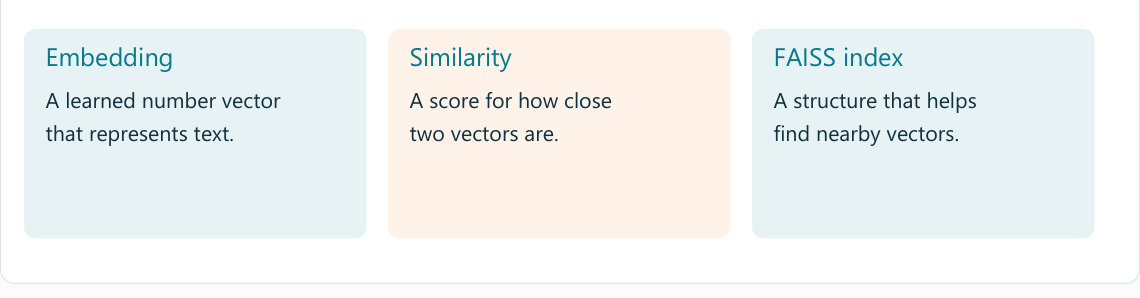

Document keeps text and source details. OllamaEmbeddings returns vectors, not chat replies.

In [5]:
from langchain_core.documents import Document
from langchain_ollama import OllamaEmbeddings

FAISS stores vectors and finds nearby vectors. Its result is linked back to source text.

In [6]:
from langchain_community.vectorstores import FAISS

One fact per line keeps the first search example easy to inspect.

In [7]:
lines = (ASSETS / "course-notes.txt").read_text(encoding="utf-8").splitlines()

enumerate gives a line position. The list creates one Document per line and keeps an evidence label.

In [8]:
docs = [Document(page_content=line, metadata={"source": "course-notes.txt", "line": i + 1}) for i, line in enumerate(lines)]

Use the same downloaded embedding model for stored facts and questions.

In [9]:
embeddings = OllamaEmbeddings(model="nomic-embed-text", base_url="http://localhost:11434")

Embed each document and build this notebook's own index. No previous day is required.

In [10]:
store = FAISS.from_documents(docs, embeddings)

In [11]:
vector = embeddings.embed_query("Which class uses tables?")

The numbers are actual learned embedding values, not handmade meanings for five words.

In [12]:
print("Vector length:", len(vector))
print("First five values:", vector[:5])

Vector length: 768
First five values: [-0.03935318, 0.029599432, -0.17174381, -0.052450363, 0.027680902]


In [13]:
matches = store.similarity_search("When can I learn Pandas?", k=2)

Inspect returned text and labels. k=2 is a small reading set for this example.

In [14]:
[(doc.page_content, doc.metadata) for doc in matches]

[('Pandas class is on Tuesday at 11:00 in Room 3.',
  {'source': 'course-notes.txt', 'line': 2}),
 ('Python class is on Monday at 10:00 in Room 2.',
  {'source': 'course-notes.txt', 'line': 1})]

Even an unrelated question has a nearest stored vector. Nearest does not mean relevant.

In [15]:
[(doc.page_content, doc.metadata) for doc in store.similarity_search("What is the weather?", k=1)]

[('Python class is on Monday at 10:00 in Room 2.',
  {'source': 'course-notes.txt', 'line': 1})]

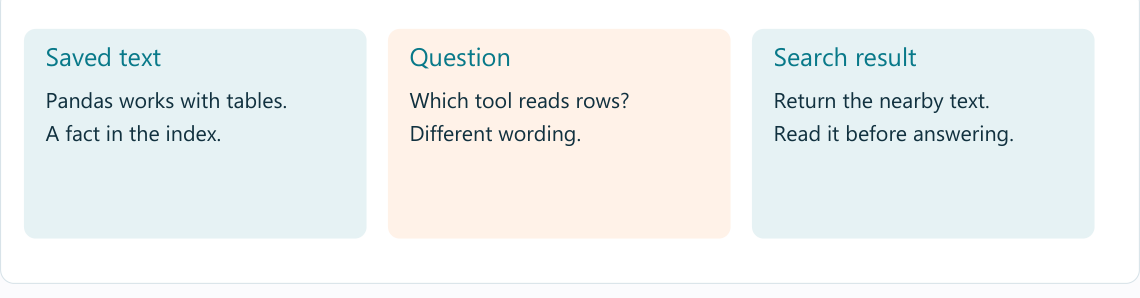

## Try a fresh input

Try an unrelated question. The nearest item may still be irrelevant.

Compare the real output with the given input. A neat format is not proof of correct facts.

## Complete KGP Talkie tutorial

Read the complete tutorial breakdown for this section in our [KGP Talkie article](https://kgptalkie.com/tutorials/generative-ai/langchain-vector-stores).